## **Практическая работа 1. Однофазная фильтрация**

Решить $B(p)p_t-\operatorname{div}(C(p)\nabla p)=0$ в прямоугольнике
$\Omega=(0,200)\times(0,100)$ м при начальном давлении $p_0=10$ МПа.
На $\Gamma_1=\{x=0,\ 50\le y\le100\}$ давление $g=18$ МПа,
на остальных сторонах поток равен нулю. Источников внутри области нет.

$B(p)=\rho_0[1+c_f(p-p_0)]\phi c_t$,

$C(p)=\rho_0[1+c_f(p-p_0)]k/\mu$.

**Дополнительное задание:** выполнить расчёт на сетках $(n_x,n_y)=(80,40)$
и $(160,80)$ и найти норму погрешности, приняв решение на мелкой сетке
за точное. Сравниваются две пары размеров, обе с квадратными ячейками.
Время расчёта $T=24$ ч, одинаковый шаг $\tau=1$ ч на обеих сетках.

In [1]:
%matplotlib inline
from dolfin import *
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from pathlib import Path

RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
set_log_level(LogLevel.ERROR)
L, H = 200., 100.
GRIDS = ((80, 40), (160, 80))
tau = 3600.
M = 24
k, mu = 5e-14, 0.001
ct, cf = 2e-9, 5e-6
fi, ro0 = 0.2, 900.
p0, g = 10e6, 18e6

### Сетка, граничные условия и вариационная задача

Каждый прямоугольник сетки делится на два треугольника одной диагональю.
Используются непрерывные кусочно-линейные элементы $P_1$.
Коэффициенты берём с прошлого слоя, давление в диффузии — с нового:

$$\int_\Omega B(p^n)p^{n+1}v\,dx
+\tau\int_\Omega C(p^n)\nabla p^{n+1}\cdot\nabla v\,dx
=\int_\Omega B(p^n)p^n v\,dx.$$

Здесь $v=0$ на $\Gamma_1$, а нулевой поток на остальных сторонах —
естественное граничное условие. У диффузионного члена знак **плюс**:
он следует из интегрирования исходного уравнения по частям.
В формулах (9.7)–(9.8) исходного PDF есть опечатка в знаке.
Начальное поле постоянно; скачок граничного давления задаётся при $t>0$.

In [2]:
class LeftTopBoundary(SubDomain):
    def inside(self, x, on_boundary):
        return on_boundary and near(x[0], 0.) and x[1] >= H/2 - DOLFIN_EPS


def B(p):
    return ro0 * (1 + cf * (p-p0)) * fi * ct


def C(p):
    return ro0 * (1 + cf * (p-p0)) / mu * k


def solve_filtration(nx, ny):
    folder = RESULTS / f'mesh_{nx}x{ny}'
    folder.mkdir(exist_ok=True)
    mesh = RectangleMesh(Point(0, 0), Point(L, H), nx, ny, 'right')
    V = FunctionSpace(mesh, 'P', 1)
    bc = DirichletBC(V, Constant(g), LeftTopBoundary())
    boundary_dofs = list(bc.get_boundary_values())
    p, v = TrialFunction(V), TestFunction(V)
    p_old = interpolate(Constant(p0), V)
    p_new = Function(V, name='pressure')
    a = B(p_old)*p*v*dx + tau*C(p_old)*inner(grad(p), grad(v))*dx
    rhs = B(p_old)*p_old*v*dx

    vtk = File(str(folder / 'pressure.pvd'))
    vtk << (p_old, 0.)
    solutions = []
    history = []
    print(f'\nСетка {nx}x{ny}: {mesh.num_cells()} треугольников, {V.dim()} узлов')
    for j in range(M):
        A, b = assemble(a), assemble(rhs)
        A_bc, b_bc = A.copy(), b.copy()
        bc.apply(A_bc, b_bc)
        solve(A_bc, p_new.vector(), b_bc, 'lu')

        # Баланс дискретной схемы: накопление = приток за шаг времени.
        # Реакция берётся из исходной системы до подстановки условия Дирихле.
        reaction = b.copy()
        A.mult(p_new.vector(), reaction)
        reaction.axpy(-1., b)
        inflow = reaction.get_local()[boundary_dofs].sum()
        storage = assemble(B(p_old)*(p_new-p_old)*dx)
        balance_error = abs(storage-inflow) / max(abs(storage), 1.)
        values = p_new.vector().get_local()
        assert np.isfinite(values).all()
        assert values.min() >= p0-1 and values.max() <= g+1
        assert balance_error < 1e-7

        t = (j+1)*tau
        mean_mpa = assemble(p_new*dx)/(L*H)/1e6
        history.append((t/3600, mean_mpa, balance_error))
        solutions.append(p_new.copy(deepcopy=True))
        vtk << (p_new, t)
        print(f't = {t/3600:2g} ч, среднее давление = {mean_mpa:.6f} МПа')
        p_old.assign(p_new)

    history = np.asarray(history)
    np.savetxt(folder / 'history.csv', history, delimiter=',',
               header='time_h,mean_pressure_mpa,balance', comments='')
    np.savez(folder / 'filtration.npz', xy=mesh.coordinates(), cells=mesh.cells(),
             p=p_new.compute_vertex_values(mesh), time=history[:, 0],
             mean_pressure=history[:, 1], balance=history[:, 2])
    return dict(nx=nx, ny=ny, mesh=mesh, V=V, solutions=solutions, history=history)

### Расчёт на двух сетках

Крупная сетка: $h_x=h_y=2.5$ м; мелкая: $h_x=h_y=1.25$ м.
На каждом временном слое решается линейная система с коэффициентами,
вычисленными по предыдущему слою. Проверяются диапазон давления и баланс.

In [3]:
coarse, fine = [solve_filtration(nx, ny) for nx, ny in GRIDS]
for result in (coarse, fine):
    print(f"{result['nx']}x{result['ny']}: максимальная ошибка баланса = "
          f"{result['history'][:, 2].max():.3e}")


Сетка 80x40: 6400 треугольников, 3321 узлов
t =  1 ч, среднее давление = 10.521433 МПа
t =  2 ч, среднее давление = 11.253756 МПа
t =  3 ч, среднее давление = 11.777176 МПа
t =  4 ч, среднее давление = 12.194285 МПа
t =  5 ч, среднее давление = 12.546915 МПа
t =  6 ч, среднее давление = 12.851779 МПа
t =  7 ч, среднее давление = 13.119099 МПа
t =  8 ч, среднее давление = 13.356392 МПа


t =  9 ч, среднее давление = 13.569275 МПа
t = 10 ч, среднее давление = 13.761994 МПа
t = 11 ч, среднее давление = 13.937818 МПа
t = 12 ч, среднее давление = 14.099308 МПа
t = 13 ч, среднее давление = 14.248502 МПа
t = 14 ч, среднее давление = 14.387046 МПа
t = 15 ч, среднее давление = 14.516286 МПа
t = 16 ч, среднее давление = 14.637332 МПа
t = 17 ч, среднее давление = 14.751112 МПа


t = 18 ч, среднее давление = 14.858405 МПа
t = 19 ч, среднее давление = 14.959870 МПа
t = 20 ч, среднее давление = 15.056072 МПа
t = 21 ч, среднее давление = 15.147495 МПа
t = 22 ч, среднее давление = 15.234558 МПа
t = 23 ч, среднее давление = 15.317625 МПа
t = 24 ч, среднее давление = 15.397014 МПа



Сетка 160x80: 25600 треугольников, 13041 узлов
t =  1 ч, среднее давление = 10.517522 МПа
t =  2 ч, среднее давление = 11.247657 МПа


t =  3 ч, среднее давление = 11.770110 МПа
t =  4 ч, среднее давление = 12.186501 МПа
t =  5 ч, среднее давление = 12.538580 МПа


...

t = 10 ч, среднее давление = 13.752403 МПа
t = 11 ч, среднее давление = 13.928141 МПа
t = 12 ч, среднее давление = 14.089574 МПа


t = 13 ч, среднее давление = 14.238736 МПа
t = 14 ч, среднее давление = 14.377268 МПа
t = 15 ч, среднее давление = 14.506510 МПа


t = 16 ч, среднее давление = 14.627571 МПа
t = 17 ч, среднее давление = 14.741376 МПа
t = 18 ч, среднее давление = 14.848701 МПа


t = 19 ч, среднее давление = 14.950206 МПа
t = 20 ч, среднее давление = 15.046452 МПа
t = 21 ч, среднее давление = 15.137925 МПа


t = 22 ч, среднее давление = 15.225041 МПа
t = 23 ч, среднее давление = 15.308165 МПа
t = 24 ч, среднее давление = 15.387614 МПа
80x40: максимальная ошибка баланса = 2.393e-13
160x80: максимальная ошибка баланса = 4.952e-12


### Норма погрешности относительно решения на мелкой сетке

Пусть $p_h$ — решение на сетке $80\times40$, $p_{h/2}$ — на $160\times80$.
Примем $p_{h/2}$ за эталон и вычислим при одинаковом времени:

$$E_{L^2}(t)=\left(\int_\Omega
[I_{h\to h/2}p_h(x,y,t)-p_{h/2}(x,y,t)]^2\,dx\,dy\right)^{1/2},$$

$$E_{\rm rel}(t)=\frac{E_{L^2}(t)}{\|p_{h/2}(t)\|_{L^2(\Omega)}},
\qquad E_{\rm RMS}(t)=\frac{E_{L^2}(t)}{\sqrt{|\Omega|}}.$$

$E_{L^2}$ имеет размерность Па·м, $E_{\rm RMS}$ — Па.
Дополнительно найдём $E_\infty=\max_{\overline\Omega}|I p_h-p_{h/2}|$ (Па).
Обе сетки имеют одинаковое направление диагоналей и вложены, поэтому
интерполяция $P_1$ на мелкую сетку точно представляет крупносеточную функцию.
Интеграл квадрата разности вычисляется на мелкой сетке; максимум модуля
кусочно-линейной разности достигается в одном из её узлов.
Это оценка расхождения по пространству при фиксированном шаге времени.
Две сетки не позволяют независимо определить порядок сходимости или
погрешность эталонного решения. Нулевая разность эталона с самим собой
не означает нулевую погрешность мелкой сетки относительно решения PDE.

In [4]:
errors = []
for row, p_h, p_ref in zip(fine['history'], coarse['solutions'], fine['solutions']):
    p_on_fine = interpolate(p_h, fine['V'])
    difference = Function(fine['V'], name='coarse_minus_fine')
    difference.vector()[:] = p_on_fine.vector().get_local() - p_ref.vector().get_local()
    measure = dx(domain=fine['mesh'], metadata={'quadrature_degree': 2})
    l2 = np.sqrt(assemble(difference*difference*measure))
    ref_l2 = np.sqrt(assemble(p_ref*p_ref*measure))
    rms = l2/np.sqrt(L*H)
    linf = np.abs(difference.vector().get_local()).max()
    errors.append((row[0], l2, l2/ref_l2, rms, linf))

errors = np.asarray(errors)
assert errors.shape == (M, 5) and np.isfinite(errors).all()
np.savetxt(RESULTS / 'errors.csv', errors, delimiter=',',
           header='time_h,l2_pa_m,relative_l2,rms_pa,linf_pa', comments='')
File(str(RESULTS / 'difference.pvd')) << (difference, M*tau)
print('\nПогрешность сетки 80x40 относительно 160x80:')
print(' t, ч    L2, Па·м       L2, %       RMS, МПа     Linf, МПа')
for hour in (1, 6, 12, 24):
    t, l2, rel, rms, linf = errors[hour-1]
    print(f'{t:5.0f}  {l2:13.6e}  {100*rel:10.6f}  {rms/1e6:11.6f}  {linf/1e6:11.6f}')


Погрешность сетки 80x40 относительно 160x80:
 t, ч    L2, Па·м       L2, %       RMS, МПа     Linf, МПа
    1   1.752786e+06    0.117074     0.012394     0.526275
    6   1.615018e+06    0.087838     0.011420     0.128723
   12   1.520478e+06    0.075772     0.010751     0.094432
   24   1.375670e+06    0.063052     0.009727     0.065692


### Визуализация решения и погрешности

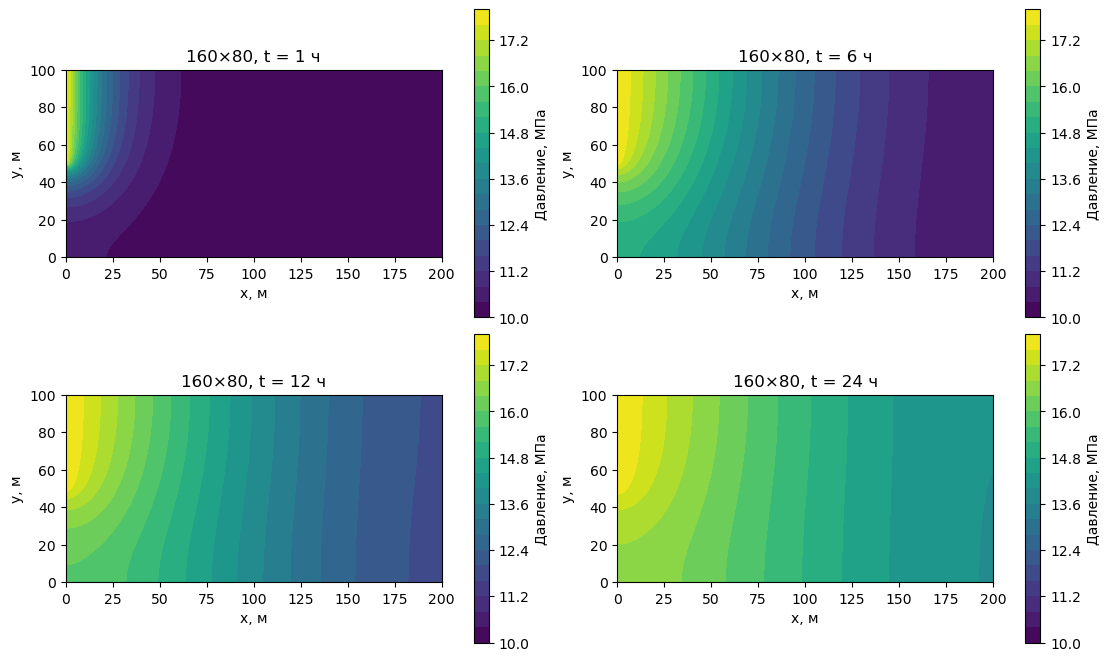

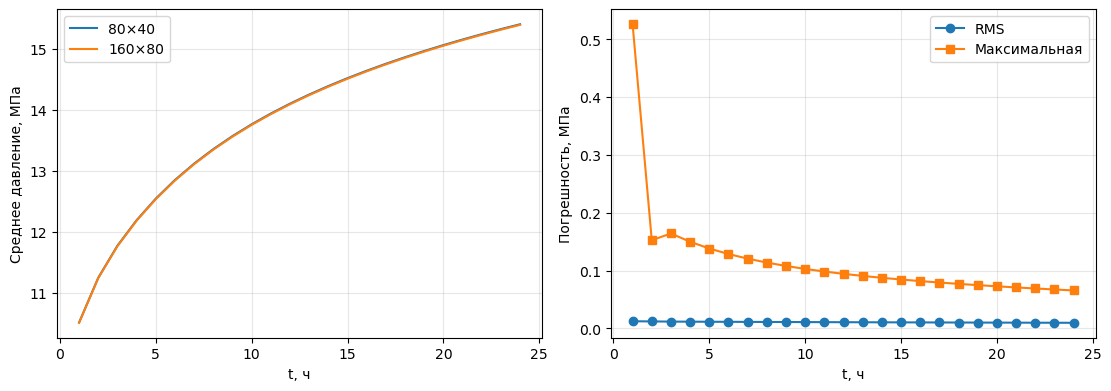

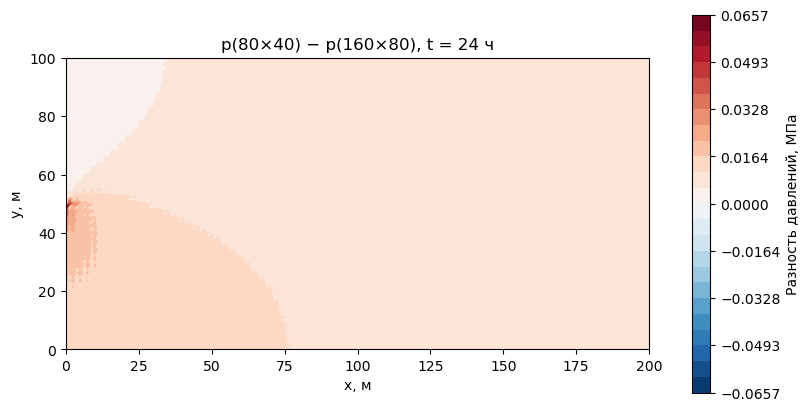

In [5]:
mesh = fine['mesh']
xy = mesh.coordinates()
tri = mtri.Triangulation(xy[:, 0], xy[:, 1], mesh.cells())
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), constrained_layout=True)
for ax, hour in zip(axes.flat, (1, 6, 12, 24)):
    values = fine['solutions'][hour-1].compute_vertex_values(mesh)
    im = ax.tricontourf(tri, values/1e6, levels=np.linspace(10, 18, 21))
    fig.colorbar(im, ax=ax, label='Давление, МПа')
    ax.set(title=f'160×80, t = {hour} ч', xlabel='x, м', ylabel='y, м', aspect='equal')
fig.savefig(RESULTS / 'filtration.png', dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for result in (coarse, fine):
    axes[0].plot(result['history'][:, 0], result['history'][:, 1],
                 label=f"{result['nx']}×{result['ny']}")
axes[0].set(xlabel='t, ч', ylabel='Среднее давление, МПа')
axes[0].legend()
axes[1].plot(errors[:, 0], errors[:, 3]/1e6, 'o-', label='RMS')
axes[1].plot(errors[:, 0], errors[:, 4]/1e6, 's-', label='Максимальная')
axes[1].set(xlabel='t, ч', ylabel='Погрешность, МПа')
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
fig.savefig(RESULTS / 'comparison.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
diff_values = difference.compute_vertex_values(mesh)/1e6
limit = np.abs(diff_values).max()
im = ax.tricontourf(tri, diff_values, levels=np.linspace(-limit, limit, 25), cmap='RdBu_r')
fig.colorbar(im, ax=ax, label='Разность давлений, МПа')
ax.set(title='p(80×40) − p(160×80), t = 24 ч', xlabel='x, м', ylabel='y, м', aspect='equal')
fig.savefig(RESULTS / 'difference.png', dpi=160)
plt.show()

### Итоговая таблица и вывод

Таблица ниже содержит результаты при $T=24$ ч. Эталон — решение 160×80.
Давление растёт от участка нагнетания; по разности полей можно оценить
влияние пространственной сетки. Файлы `errors.csv` и `summary.csv`
содержат нормы по времени и итоговые характеристики соответственно.

При $T=24$ ч среднее давление равно **15.397014 МПа** на сетке 80×40
и **15.387614 МПа** на сетке 160×80. Для крупной сетки:
$E_{L^2}=1.375670\cdot10^6$ Па·м, $E_{\rm rel}=0.063052\%$,
$E_{\rm RMS}=0.009727$ МПа, $E_\infty=0.065692$ МПа.
Относительная норма рассчитана по полному давлению эталона.

$c_f=5\cdot10^{-6}$ взят буквально из задания: $c_f(g-p_0)=40$.
При этих данных предположение о малом изменении плотности не выполняется;
расчёт сохраняет учебные параметры. Проверяется баланс выбранной схемы
с коэффициентами с предыдущего слоя.

In [6]:
summary = []
for result, error in ((coarse, errors[-1, 1:]), (fine, np.zeros(4))):
    summary.append((result['nx'], result['ny'], result['V'].dim(),
                    L/result['nx'], H/result['ny'], result['history'][-1, 1], *error))
summary = np.asarray(summary)
np.savetxt(RESULTS / 'summary.csv', summary, delimiter=',',
           header='nx,ny,nodes,hx_m,hy_m,mean_pressure_mpa,l2_pa_m,relative_l2,rms_pa,linf_pa',
           comments='')
print('\nРезультаты при T = 24 ч:')
for row in summary:
    nx, ny, nodes, hx, hy, mean, l2, rel, rms, linf = row
    print(f'{nx:.0f}x{ny:.0f}: {nodes:.0f} узлов, h = {hx:g} м, '
          f'среднее p = {mean:.6f} МПа, L2 = {l2:.6e} Па·м, '
          f'относительная L2 = {100*rel:.6f} %, RMS = {rms/1e6:.6f} МПа')
print('Нули в строке 160x80 означают сравнение эталона с самим собой.')
print('cf·Δp =', cf*(g-p0))

# Прежние пути результатов теперь содержат решение на мелкой сетке.
np.savez(RESULTS / 'filtration.npz', xy=xy, cells=mesh.cells(),
         p=fine['solutions'][-1].compute_vertex_values(mesh), time=fine['history'][:, 0],
         mean_pressure=fine['history'][:, 1], balance=fine['history'][:, 2])
np.savetxt(RESULTS / 'history.csv', fine['history'], delimiter=',',
           header='time_h,mean_pressure_mpa,balance', comments='')


Результаты при T = 24 ч:
80x40: 3321 узлов, h = 2.5 м, среднее p = 15.397014 МПа, L2 = 1.375670e+06 Па·м, относительная L2 = 0.063052 %, RMS = 0.009727 МПа
160x80: 13041 узлов, h = 1.25 м, среднее p = 15.387614 МПа, L2 = 0.000000e+00 Па·м, относительная L2 = 0.000000 %, RMS = 0.000000 МПа
Нули в строке 160x80 означают сравнение эталона с самим собой.
cf·Δp = 40.0
